<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_13_Words_Similarity_via_distance_and_cosine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# Part_1:Cosine Similarity vs Euclidean Distance

## Task_1:
- At each of 1000 iterations, create two vectors of 768 random numbers
drawn from a standard normal distribution, calculate cosine similarity
and Euclidean distance by translating the equations into code, and
store the results. Without generating new random data, repeat the
calculation for three cases within each iteration:
1. Standard random numbers (mean of zero, standard deviation
of one).
2. Shrink the standard deviation of one variable by dividing the
vector by 10 without changing the other vector.
3. Divide both vectors by their norm so that both vectors have a
norm of 1.
Visualize the results in one scatter plot as in Figure 3.23, and then
re-plot the same data in three separate panels as in Figure 3.24

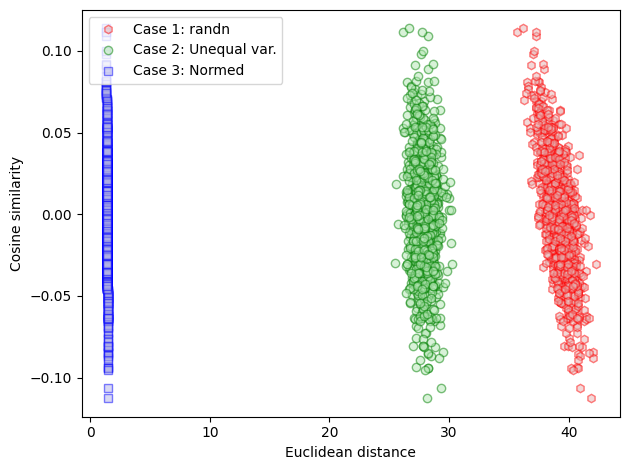

In [3]:
# simulation parameters
M = 768
k = 1000

# initializations
cs = np.zeros((k,3))
dist = np.zeros((k,3))

# loop over simulation iterations
for i in range(k):

  # create the data
  x = np.random.normal(0,1,M)
  y = np.random.normal(0,1,M)

  # case 1: normal random
  dist[i,0] = np.sqrt( np.sum( (x-y)**2 ) )
  cs[i,0] = np.dot(x,y) / (np.linalg.norm(x)*np.linalg.norm(y))

  # case 2: different variances
  x /= 10
  dist[i,1] = np.sqrt( np.sum( (x-y)**2 ) )
  cs[i,1] = np.dot(x,y) / (np.linalg.norm(x)*np.linalg.norm(y))

  # case 3: normalized
  x = x/np.linalg.norm(x)
  y = y/np.linalg.norm(y)
  dist[i,2] = np.sqrt( np.sum( (x-y)**2 ) )
  cs[i,2] = np.dot(x,y) # need the norm-scaling?


# the first plot
plt.plot(dist[:,0],cs[:,0],'rh',markerfacecolor=[.9,.7,.7,.5],label='Case 1: randn')
plt.plot(dist[:,1],cs[:,1],'go',markerfacecolor=[.7,.9,.7,.5],label='Case 2: Unequal var.')
plt.plot(dist[:,2],cs[:,2],'bs',markerfacecolor=[.7,.7,.9,.5],label='Case 3: Normed')

plt.gca().set(xlabel='Euclidean distance',ylabel='Cosine similarity')
plt.legend()

plt.tight_layout()
plt.show()

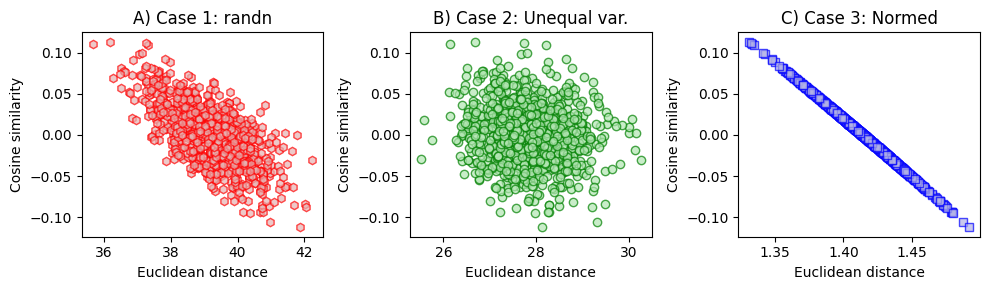

In [4]:

# the second plot
_,axs = plt.subplots(1,3,figsize=(10,3))

axs[0].plot(dist[:,0],cs[:,0],'rh',markerfacecolor=[.9,.7,.7,.7])
axs[0].set(xlabel='Euclidean distance',ylabel='Cosine similarity',title='A) Case 1: randn')

axs[1].plot(dist[:,1],cs[:,1],'go',markerfacecolor=[.7,.9,.7,.7])
axs[1].set(xlabel='Euclidean distance',ylabel='Cosine similarity',title='B) Case 2: Unequal var.')

axs[2].plot(dist[:,2],cs[:,2],'bs',markerfacecolor=[.7,.7,.9,.7])
axs[2].set(xlabel='Euclidean distance',ylabel='Cosine similarity',title='C) Case 3: Normed')

plt.tight_layout()
plt.show()

# Part_2:Relationship Between Similarity and Distance

## Task_1:
- Using pen and paper, rewrite the squared Euclidean distance
(Equation 3.9) as a function of cosine similarity (Equation 3.8).
Assume that the vectors are normalized, such that x⊤x = y⊤y = 1

## Task_2:
- Implement Equation 3.13 in code. To confirm the accuracy of the
equation, subtract the left-hand-side from the right-hand-side, and
plot the differences for the 1000 vector pairs you created in Part
1. The differences should all be zero within a reasonable numerical
precision tolerance of around 10−15.

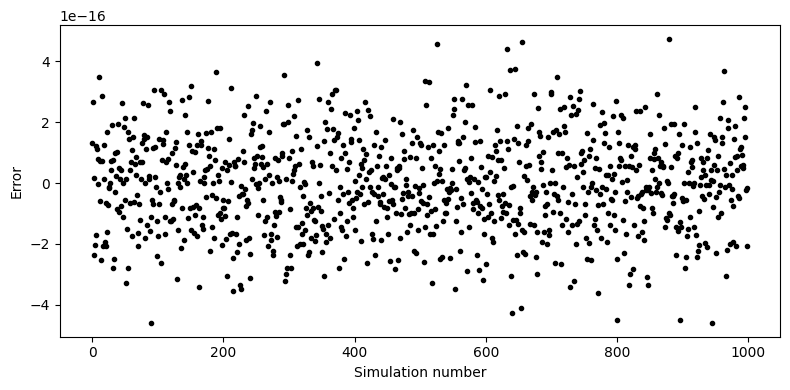

In [5]:

# apply equation 1.13 to Case 3 (both vectors normed)
eq13 = cs[:,2] - (1-dist[:,2]**2/2)

plt.figure(figsize=(8,4))
plt.plot(eq13,'k.')
plt.gca().set(xlabel='Simulation number',ylabel='Error')

# note the y-axis, then use the same y-axis as in Part 1
# plt.ylim([-.1,.1])

plt.tight_layout()
plt.show()

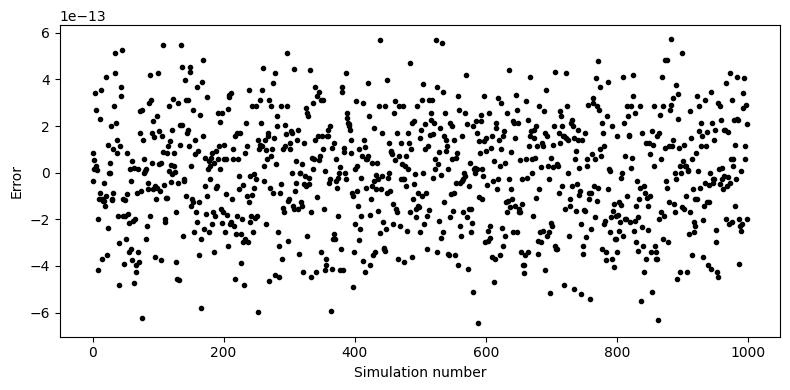

In [6]:
# errors (difference between RHS and LHS)
e = np.zeros(k)

# loop over simulation iterations
for i in range(k):

  # create the data
  x = np.random.normal(0,1,M)
  y = np.random.normal(0,1,M)

  # case 1: normal random
  d = np.sqrt( np.sum( (x-y)**2 ) )
  s = np.dot(x,y)/(np.linalg.norm(x)*np.linalg.norm(y))

  xtx = x.T@x
  yty = y.T@y

  # Equation 1.14
  den = np.sqrt(xtx) * np.sqrt(yty)
  rhs = xtx/den + yty/den - d**2/den
  e[i] = 2*s - rhs

  # Equation 1.15 (comment out to run 1.14)
  e[i] = 2*x.T@y - (xtx + yty - d**2)


# and plot
plt.figure(figsize=(8,4))
plt.plot(e,'k.')
plt.gca().set(xlabel='Simulation number',ylabel='Error')

plt.tight_layout()
plt.show()

# Part_3: Word Synonyms via distance and Similarity

## Task_1:
- Import the bert-large-uncased model and tokenizer. Extract the
embeddings matrix.
Choose a “seed” word and confirm that it is encoded using
one token (I used “beauty”). Calculate cosine similarity and Eu
clidean distance from its embeddings vector to all other embeddings
vectors. Replace the trivial self-distance and self-similarity values
with NaN.
Visualize the results in scatter plots as in Figure 3.25. Create
a copy of the seeded distance and similarity vectors that are
min-max scaled to index the plasma color map. “Min-max scaling”
means to re-scale a data vector to have a minimum value of 0 and a
94 (§3.13)
maximum value of 1